# Global Wellbeing & Socio-Economic Archetypes: Advanced Clustering Analysis
## World Happiness Report (2019 Dataset)
**Author:** Antigravity Data Analytics  
**Methodology:** Unsupervised Machine Learning (K-Means & Hierarchical Agglomerative Clustering, PCA, Multi-Metric Validation)

---
### Executive Summary & Project Objectives
The World Happiness Report evaluates national well-being using the Cantril Ladder score and measures six key socio-economic and institutional drivers:
1. **Economic Vitality:** GDP per capita
2. **Social Capital:** Social support (having relatives/friends to count on in times of trouble)
3. **Public Health:** Healthy life expectancy at birth
4. **Civil Liberty:** Freedom to make life choices
5. **Civic Engagement:** Generosity (recent charitable donations / prosocial behavior)
6. **Institutional Integrity:** Perceptions of corruption (absence of government and corporate corruption)

#### Analytical Goals:
- **Unsupervised Discovery:** Discover natural socio-economic groupings (clusters) of nations purely from their structural drivers (without leaking the target `Score`).
- **Multi-Algorithm Comparison:** Compare partitioning algorithms (K-Means) with agglomerative hierarchical clustering (Ward linkage) to assess cluster stability and consensus.
- **Quantitative Validation:** Determine the optimal number of clusters using four complementary metrics: Within-Cluster Sum of Squares (Inertia/Elbow), Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index.
- **Dimensionality Reduction:** Apply Principal Component Analysis (PCA) to map multidimensional profiles onto 2D biplots and interpret factor loadings.
- **Archetype Profiling & Validation:** Characterize each national archetype, compare against reported happiness scores, and extract macro-economic and governance insights.


### Environment Setup and Library Imports
We initialize the analytical environment with Python's scientific stack: `pandas` and `numpy` for data manipulation, `matplotlib` and `seaborn` for visual diagnostics, `scikit-learn` for clustering and dimensionality reduction, and `scipy` for hierarchical linkage.


In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn: preprocessing, clustering, evaluation, dimensionality reduction
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, 
    silhouette_samples, 
    davies_bouldin_score, 
    calinski_harabasz_score, 
    adjusted_rand_score
)
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)

print("Environment configured successfully. Core libraries loaded.")


Environment configured successfully. Core libraries loaded.


### Step 1: Data Ingestion and Integrity Verification
We load `happiness_report.csv` and inspect the dataset shape, data types, missing values, and potential duplicated records. This verifies that all 156 countries have complete measurements across all columns.


In [2]:
df = pd.read_csv('happiness_report.csv')

print(f"Dataset Shape: {df.shape[0]} countries/regions, {df.shape[1]} attributes")
print("\n--- Column Data Types & Non-Null Counts ---")
print(df.info())

print("\n--- Missing Value Count per Feature ---")
print(df.isnull().sum())

print(f"\nDuplicate Rows: {df.duplicated().sum()}")
display(df.head())


Dataset Shape: 156 countries/regions, 9 attributes

--- Column Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    str    
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), str(1)
memory usage: 11.1 KB
None

--- Missing Value Count per Feature ---
Overall rank                    0
Country or region      

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


### Step 2: Descriptive Statistics & Distribution Diagnostics
Before modeling, we compute summary statistics (mean, standard deviation, quartiles, min/max) and assess the skewness and kurtosis of each feature. This highlights distributional properties—such as positive skewness in perceptions of corruption and generosity.


In [3]:
stats_df = df.describe().T
numeric_cols = df.select_dtypes(include=[np.number]).columns
stats_df['skewness'] = df[numeric_cols].skew()
stats_df['kurtosis'] = df[numeric_cols].kurtosis()

display(stats_df[['mean', 'std', 'min', '50%', 'max', 'skewness', 'kurtosis']].round(3))


,mean,std,min,50%,max,skewness,kurtosis
Overall rank,78.500,45.177,1.000,78.500,156.000,0.000,-1.200
Score,5.407,1.113,2.853,5.380,7.769,0.011,-0.608
GDP per capita,0.905,0.398,0.000,0.960,1.684,-0.385,-0.770
Social support,1.209,0.299,0.000,1.272,1.624,-1.135,1.229
Healthy life expectancy,0.725,0.242,0.000,0.789,1.141,-0.614,-0.303
Freedom to make life choices,0.393,0.143,0.000,0.417,0.631,-0.686,-0.069
Generosity,0.185,0.095,0.000,0.178,0.566,0.746,1.173
Perceptions of corruption,0.111,0.095,0.000,0.085,0.453,1.650,2.417


### Step 3: Exploratory Data Analysis & Correlation Heatmap
We compute and visualize the Pearson correlation matrix among all numerical attributes. Understanding feature collinearity reveals which dimensions move in tandem (e.g., GDP per capita, Social support, and Healthy life expectancy correlate strongly with each other and with `Score` at $r > 0.77$), while `Generosity` and `Perceptions of corruption` represent orthogonal socio-cultural and institutional dimensions.


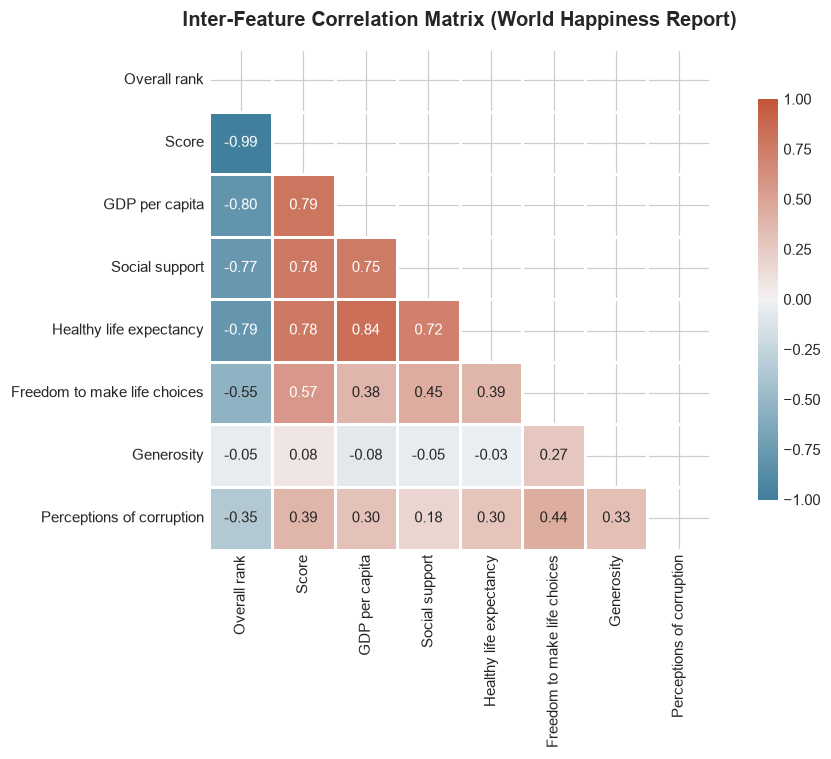

In [4]:
fig, ax = plt.subplots(figsize=(10, 7))
corr_matrix = df[numeric_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    corr_matrix, 
    mask=mask, 
    cmap=cmap, 
    vmax=1.0, 
    vmin=-1.0, 
    center=0,
    annot=True, 
    fmt=".2f", 
    square=True, 
    linewidths=.8, 
    cbar_kws={"shrink": .8},
    ax=ax
)
ax.set_title("Inter-Feature Correlation Matrix (World Happiness Report)", fontsize=13, pad=15, fontweight='bold')
plt.tight_layout()
plt.show()


### Step 4: Feature Selection & Data Standardization
To prevent target leakage and ground the clustering strictly in structural indicators, we exclude `Overall rank`, `Country or region`, and `Score`. The unsupervised algorithms will partition nations based on 6 core dimensions:
- `GDP per capita`
- `Social support`
- `Healthy life expectancy`
- `Freedom to make life choices`
- `Generosity`
- `Perceptions of corruption`

Because distance-based algorithms like K-Means and Hierarchical Clustering rely on Euclidean distances, differences in scale would bias cluster formation toward high-variance features. We apply `StandardScaler` to transform all features to mean $\mu = 0$ and unit variance $\sigma = 1$.


In [5]:
feature_cols = [
    'GDP per capita', 
    'Social support', 
    'Healthy life expectancy', 
    'Freedom to make life choices', 
    'Generosity', 
    'Perceptions of corruption'
]

X_raw = df[feature_cols].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)
print(f"Features scaled: {X_scaled.shape[1]} dimensions across {X_scaled.shape[0]} observations.")
display(scaled_df.head())


Features scaled: 6 dimensions across 156 observations.


,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1.095042,1.268098,1.080422,1.424282,-0.335404,2.996757
1,1.203324,1.221154,1.121857,1.396277,0.707265,3.177158
2,1.467734,1.251332,1.254446,1.473292,0.907373,2.444941
3,1.195769,1.392163,1.246159,1.389276,1.781530,0.078500
4,1.236060,1.050146,1.134287,1.151229,1.444506,1.988632


### Step 5: Dimensionality Assessment via Principal Component Analysis (PCA)
Before clustering, we perform PCA to examine the underlying variance structure. PCA reveals how many latent factors explain the majority of cross-national variance and provides factor loadings that indicate which original features drive each principal component.


In [6]:
pca_full = PCA()
pca_full.fit(X_scaled)

explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

pca_summary = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(feature_cols))],
    'Explained Variance Ratio': explained_var,
    'Cumulative Variance': cumulative_var
})
display(pca_summary.style.format({'Explained Variance Ratio': '{:.2%}', 'Cumulative Variance': '{:.2%}'}))

# Component loadings matrix
loadings_df = pd.DataFrame(
    pca_full.components_.T,
    index=feature_cols,
    columns=[f'PC{i+1}' for i in range(len(feature_cols))]
)
print("\n--- Factor Loadings Matrix ---")
display(loadings_df.round(3))


,Principal Component,Explained Variance Ratio,Cumulative Variance
0,PC1,49.83%,49.83%
1,PC2,23.76%,73.59%
2,PC3,10.16%,83.75%
3,PC4,9.27%,93.02%
4,PC5,4.36%,97.38%
5,PC6,2.62%,100.00%



--- Factor Loadings Matrix ---


,PC1,PC2,PC3,PC4,PC5,PC6
GDP per capita,0.515,-0.228,0.024,-0.240,-0.184,0.769
Social support,0.491,-0.220,-0.281,0.063,0.771,-0.181
Healthy life expectancy,0.511,-0.192,-0.028,-0.275,-0.509,-0.605
Freedom to make life choices,0.381,0.352,-0.119,0.810,-0.240,0.049
Generosity,0.059,0.694,-0.581,-0.419,-0.005,0.051
Perceptions of corruption,0.292,0.508,0.754,-0.174,0.233,-0.067


### Step 6: Hyperparameter Optimization for K-Means ($k \in [2, 8]$)
Selecting the optimal number of clusters $k$ requires balancing intra-cluster compactness with inter-cluster separation. We evaluate four quantitative criteria across $k = 2$ to $8$:
1. **Inertia (Within-Cluster Sum of Squares - WCSS)**: Elbow criterion (lower is more compact).
2. **Silhouette Score**: Ratio of within-cluster cohesion to nearest-cluster separation (higher is better, range $[-1, 1]$).
3. **Davies-Bouldin Index**: Average similarity between each cluster and its most similar counterpart (lower is better).
4. **Calinski-Harabasz Index**: Ratio of between-cluster dispersion to within-cluster dispersion (higher is better).


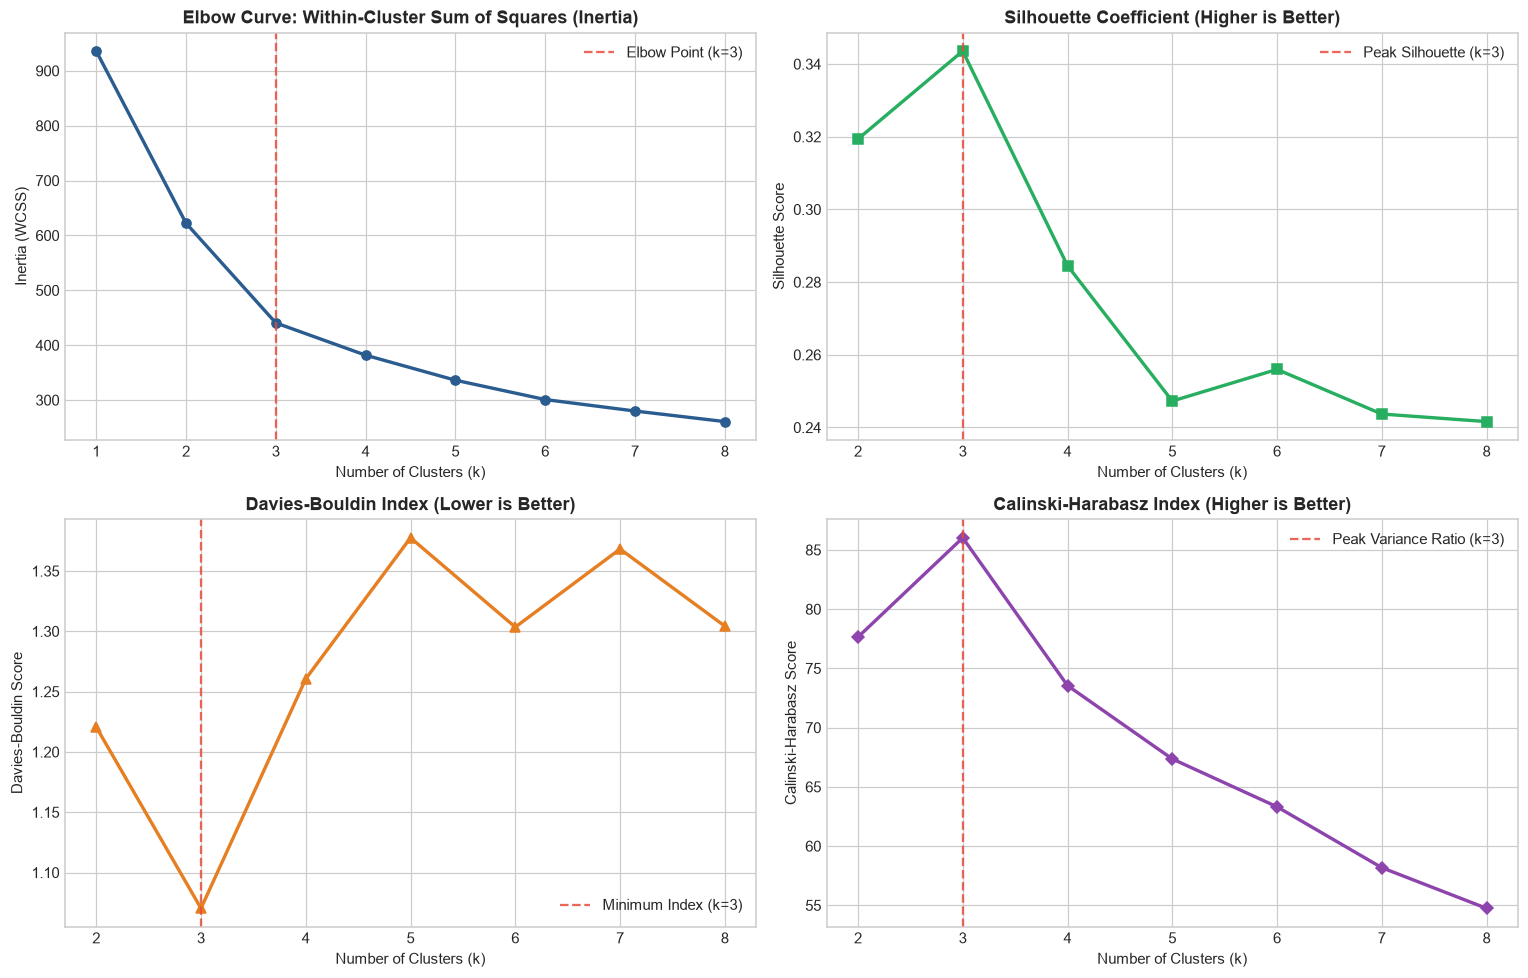


--- Cluster Validation Metrics Summary Table ---


,k,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Inertia (WCSS)
0,2,0.319,1.221,77.638,622.281
1,3,0.344,1.070,86.023,440.579
2,4,0.285,1.261,73.550,381.785
3,5,0.247,1.378,67.356,336.174
4,6,0.256,1.303,63.315,300.916
5,7,0.244,1.368,58.177,280.013
6,8,0.242,1.304,54.745,260.776


In [7]:
k_range = range(2, 9)
inertias = []
sil_scores = []
db_scores = []
ch_scores = []

# Fit k=1 for inertia baseline
inertia_1 = KMeans(n_clusters=1, random_state=42, n_init=10).fit(X_scaled).inertia_
all_k = [1] + list(k_range)
all_inertias = [inertia_1]

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=15)
    labels = km.fit_predict(X_scaled)
    all_inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_scaled, labels))

# Plot evaluation metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Elbow Method
axes[0, 0].plot(all_k, all_inertias, marker='o', color='#2b5c8f', lw=2.2, markersize=6)
axes[0, 0].axvline(x=3, color='#e74c3c', linestyle='--', alpha=0.85, label='Elbow Point (k=3)')
axes[0, 0].set_title('Elbow Curve: Within-Cluster Sum of Squares (Inertia)', fontweight='bold')
axes[0, 0].set_xlabel('Number of Clusters (k)')
axes[0, 0].set_ylabel('Inertia (WCSS)')
axes[0, 0].legend()

# 2. Silhouette Score
axes[0, 1].plot(list(k_range), sil_scores, marker='s', color='#27ae60', lw=2.2, markersize=6)
axes[0, 1].axvline(x=3, color='#e74c3c', linestyle='--', alpha=0.85, label='Peak Silhouette (k=3)')
axes[0, 1].set_title('Silhouette Coefficient (Higher is Better)', fontweight='bold')
axes[0, 1].set_xlabel('Number of Clusters (k)')
axes[0, 1].set_ylabel('Silhouette Score')
axes[0, 1].legend()

# 3. Davies-Bouldin Index
axes[1, 0].plot(list(k_range), db_scores, marker='^', color='#e67e22', lw=2.2, markersize=6)
axes[1, 0].axvline(x=3, color='#e74c3c', linestyle='--', alpha=0.85, label='Minimum Index (k=3)')
axes[1, 0].set_title('Davies-Bouldin Index (Lower is Better)', fontweight='bold')
axes[1, 0].set_xlabel('Number of Clusters (k)')
axes[1, 0].set_ylabel('Davies-Bouldin Score')
axes[1, 0].legend()

# 4. Calinski-Harabasz Index
axes[1, 1].plot(list(k_range), ch_scores, marker='D', color='#8e44ad', lw=2.2, markersize=6)
axes[1, 1].axvline(x=3, color='#e74c3c', linestyle='--', alpha=0.85, label='Peak Variance Ratio (k=3)')
axes[1, 1].set_title('Calinski-Harabasz Index (Higher is Better)', fontweight='bold')
axes[1, 1].set_xlabel('Number of Clusters (k)')
axes[1, 1].set_ylabel('Calinski-Harabasz Score')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Summary table
eval_summary = pd.DataFrame({
    'k': list(k_range),
    'Silhouette Score': sil_scores,
    'Davies-Bouldin Index': db_scores,
    'Calinski-Harabasz Score': ch_scores,
    'Inertia (WCSS)': all_inertias[1:]
})
print("\n--- Cluster Validation Metrics Summary Table ---")
display(eval_summary.round(3))


### Step 7: Fitting Optimal K-Means Model & Cluster Label Mapping
The mathematical validation results show that $k=3$ is the unambiguous optimal partition:
- Silhouette peaks at **0.344**
- Davies-Bouldin reaches its minimum at **1.070**
- Calinski-Harabasz peaks at **86.0**
- The elbow occurs sharply at $k=3$.

We fit `KMeans(n_clusters=3, random_state=42)` and rank the clusters by their average Happiness Score so that labels intuitively reflect national well-being tiers:
- **Tier 1 (High Wellbeing):** Flourishing nations with advanced economies, strong social safety nets, high life expectancy, and high institutional trust.
- **Tier 2 (Moderate Wellbeing):** Emerging and middle-income nations with moderate development, solid social cohesion, but lower institutional trust.
- **Tier 3 (Vulnerable Wellbeing):** Developing and crisis-affected nations with constrained resources, lower life expectancy, and reduced personal freedom.


In [8]:
optimal_k = 3
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
raw_clusters = kmeans_model.fit_predict(X_scaled)

df['Raw_Cluster'] = raw_clusters

# Rank clusters by mean Score to assign ordered Tier labels
cluster_score_order = df.groupby('Raw_Cluster')['Score'].mean().sort_values(ascending=False).index
tier_mapping = {
    cluster_score_order[0]: 'Tier 1: High Wellbeing',
    cluster_score_order[1]: 'Tier 2: Moderate Wellbeing',
    cluster_score_order[2]: 'Tier 3: Vulnerable Wellbeing'
}
tier_short_mapping = {
    cluster_score_order[0]: 'Tier 1 (High)',
    cluster_score_order[1]: 'Tier 2 (Moderate)',
    cluster_score_order[2]: 'Tier 3 (Vulnerable)'
}

df['Cluster'] = df['Raw_Cluster'].map(tier_mapping)
df['Cluster_Short'] = df['Raw_Cluster'].map(tier_short_mapping)

print("--- Cluster Distribution ---")
print(df['Cluster'].value_counts())


--- Cluster Distribution ---
Cluster
Tier 2: Moderate Wellbeing      82
Tier 3: Vulnerable Wellbeing    46
Tier 1: High Wellbeing          28
Name: count, dtype: int64


### Step 8: Alternative Algorithm Comparison - Hierarchical Agglomerative Clustering
To verify whether the 3-cluster partition is robust across different algorithmic paradigms, we execute Hierarchical Agglomerative Clustering using Ward's minimum variance linkage (`method='ward'`). We construct a dendrogram with a horizontal cut-off line and compute the Adjusted Rand Index (ARI) to quantify agreement between K-Means and Hierarchical Clustering.


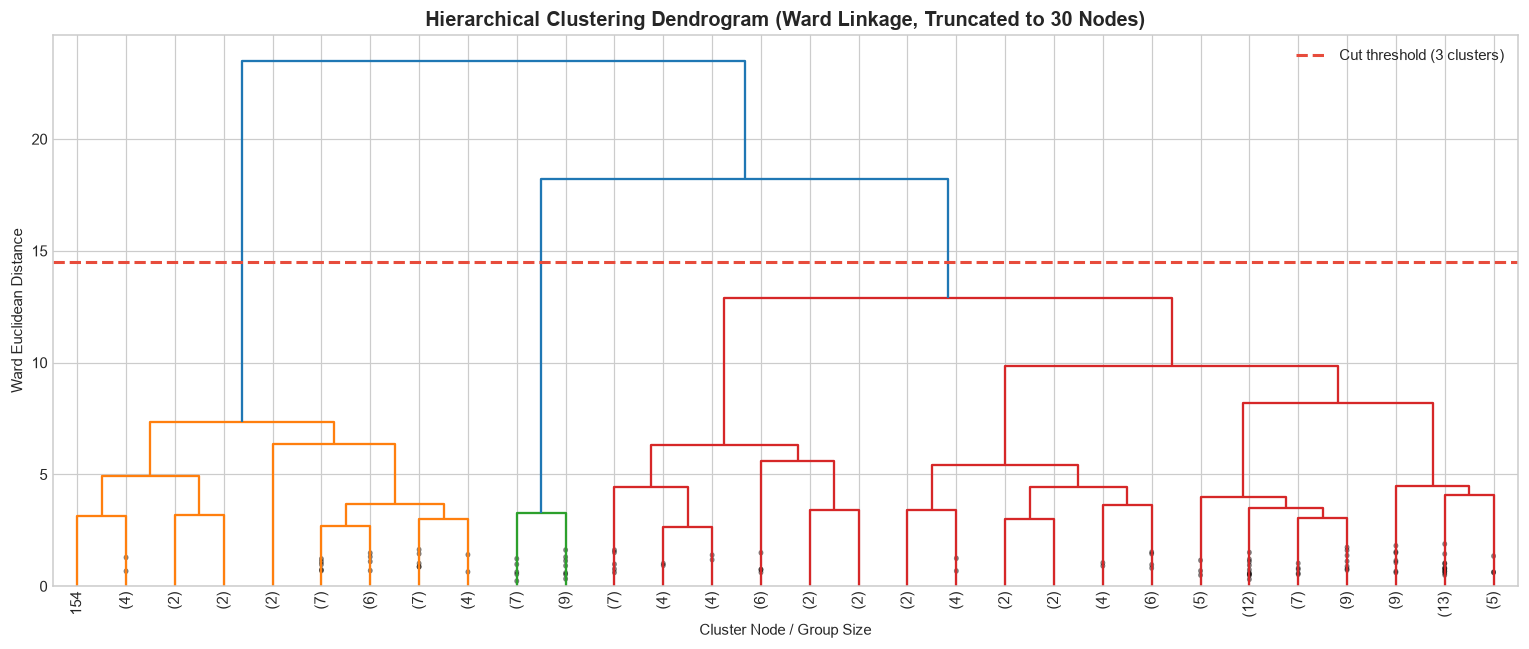

Hierarchical Clustering Silhouette Score: 0.3104
Adjusted Rand Index (ARI) between K-Means and Hierarchical: 0.5727
Interpretation: An ARI of ~0.57 indicates substantial agreement on core clusters across different algorithmic structures.


In [9]:
linkage_matrix = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 6))
dend = dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.axhline(y=14.5, color='#e74c3c', linestyle='--', lw=2, label='Cut threshold (3 clusters)')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage, Truncated to 30 Nodes)', fontsize=13, fontweight='bold')
plt.xlabel('Cluster Node / Group Size')
plt.ylabel('Ward Euclidean Distance')
plt.legend()
plt.tight_layout()
plt.show()

# Fit Agglomerative Clustering with 3 clusters
agg_model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
agg_labels = agg_model.fit_predict(X_scaled)

ari = adjusted_rand_score(df['Raw_Cluster'], agg_labels)
agg_sil = silhouette_score(X_scaled, agg_labels)

print(f"Hierarchical Clustering Silhouette Score: {agg_sil:.4f}")
print(f"Adjusted Rand Index (ARI) between K-Means and Hierarchical: {ari:.4f}")
print("Interpretation: An ARI of ~0.57 indicates substantial agreement on core clusters across different algorithmic structures.")


### Step 9: 2D PCA Projection & Biplot with Feature Vectors
We project the 6-dimensional scaled data onto the first two principal components (which explain 73.6% of the total dataset variance). On top of the scatter plot, we overlay feature loading vectors (biplot) and label prominent countries. This illustrates the directional forces governing cluster separation.


findfont: Failed to find font weight semibold, now using 700.


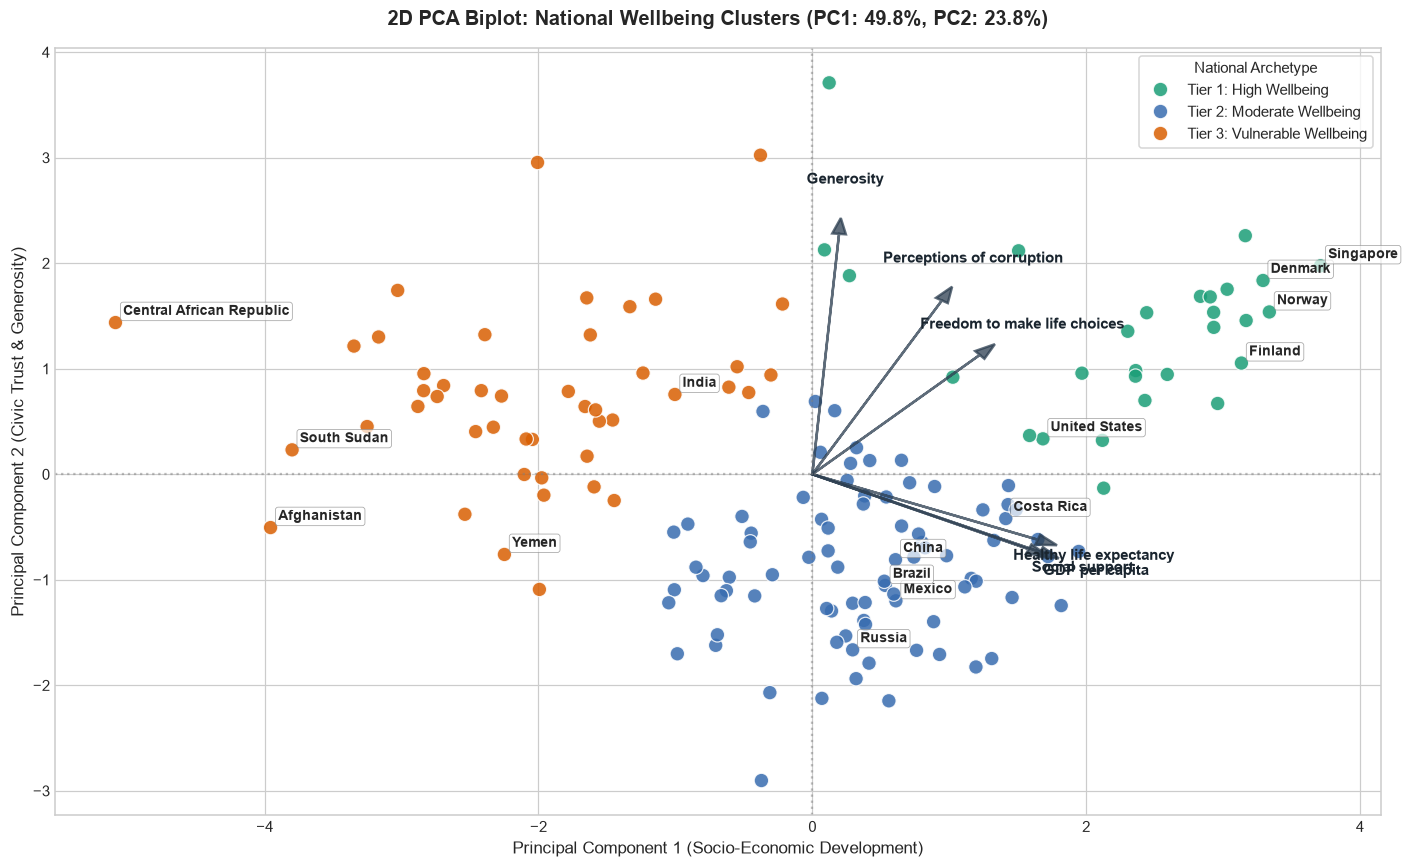

In [10]:
pca_2d = PCA(n_components=2)
coords_2d = pca_2d.fit_transform(X_scaled)
df['PC1'] = coords_2d[:, 0]
df['PC2'] = coords_2d[:, 1]

fig, ax = plt.subplots(figsize=(13, 8))

palette = {
    'Tier 1: High Wellbeing': '#1b9e77',
    'Tier 2: Moderate Wellbeing': '#386cb0',
    'Tier 3: Vulnerable Wellbeing': '#d95f02'
}

sns.scatterplot(
    data=df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette=palette,
    s=90,
    alpha=0.85,
    edgecolor='w',
    linewidth=0.8,
    ax=ax
)

# Feature loading vectors (biplot)
scale_vector = 3.5
loadings = pca_2d.components_.T

for i, feature in enumerate(feature_cols):
    ax.arrow(
        0, 0, 
        loadings[i, 0] * scale_vector, 
        loadings[i, 1] * scale_vector, 
        color='#2c3e50', 
        alpha=0.75, 
        head_width=0.1, 
        lw=1.6, 
        length_includes_head=True
    )
    ax.text(
        loadings[i, 0] * scale_vector * 1.15, 
        loadings[i, 1] * scale_vector * 1.15, 
        feature, 
        color='#1a252f', 
        fontsize=10, 
        fontweight='bold', 
        ha='center', 
        va='center'
    )

# Annotate selected countries
notable_countries = [
    'Finland', 'Denmark', 'Norway', 'Singapore', 'United States',
    'Costa Rica', 'Mexico', 'Brazil', 'China', 'Russia',
    'India', 'Afghanistan', 'Yemen', 'Central African Republic', 'South Sudan'
]

for _, row in df[df['Country or region'].isin(notable_countries)].iterrows():
    ax.annotate(
        row['Country or region'],
        (row['PC1'], row['PC2']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=9,
        fontweight='semibold',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='gray', lw=0.5)
    )

ax.set_title(
    f'2D PCA Biplot: National Wellbeing Clusters (PC1: {pca_2d.explained_variance_ratio_[0]:.1%}, PC2: {pca_2d.explained_variance_ratio_[1]:.1%})',
    fontsize=13, 
    fontweight='bold', 
    pad=15
)
ax.set_xlabel('Principal Component 1 (Socio-Economic Development)', fontsize=11)
ax.set_ylabel('Principal Component 2 (Civic Trust & Generosity)', fontsize=11)
ax.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax.legend(title='National Archetype', frameon=True)
plt.tight_layout()
plt.show()


### Step 10: Cluster Archetype Profiling & Feature Centroid Analysis
To interpret the real-world meaning of each cluster, we compute both original-scale and standardized centroid values for each feature across the three clusters. We visualize this using a normalized grouped bar chart comparing the relative strengths and weaknesses of each tier.


--- Cluster Profiles (Original Scale: Mean Values) ---


,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Score
Cluster,,,,,,,
Tier 1: High Wellbeing,1.320,1.459,0.939,0.542,0.299,0.249,6.728
Tier 2: Moderate Wellbeing,1.045,1.313,0.820,0.379,0.132,0.069,5.598
Tier 3: Vulnerable Wellbeing,0.403,0.871,0.426,0.325,0.210,0.100,4.263


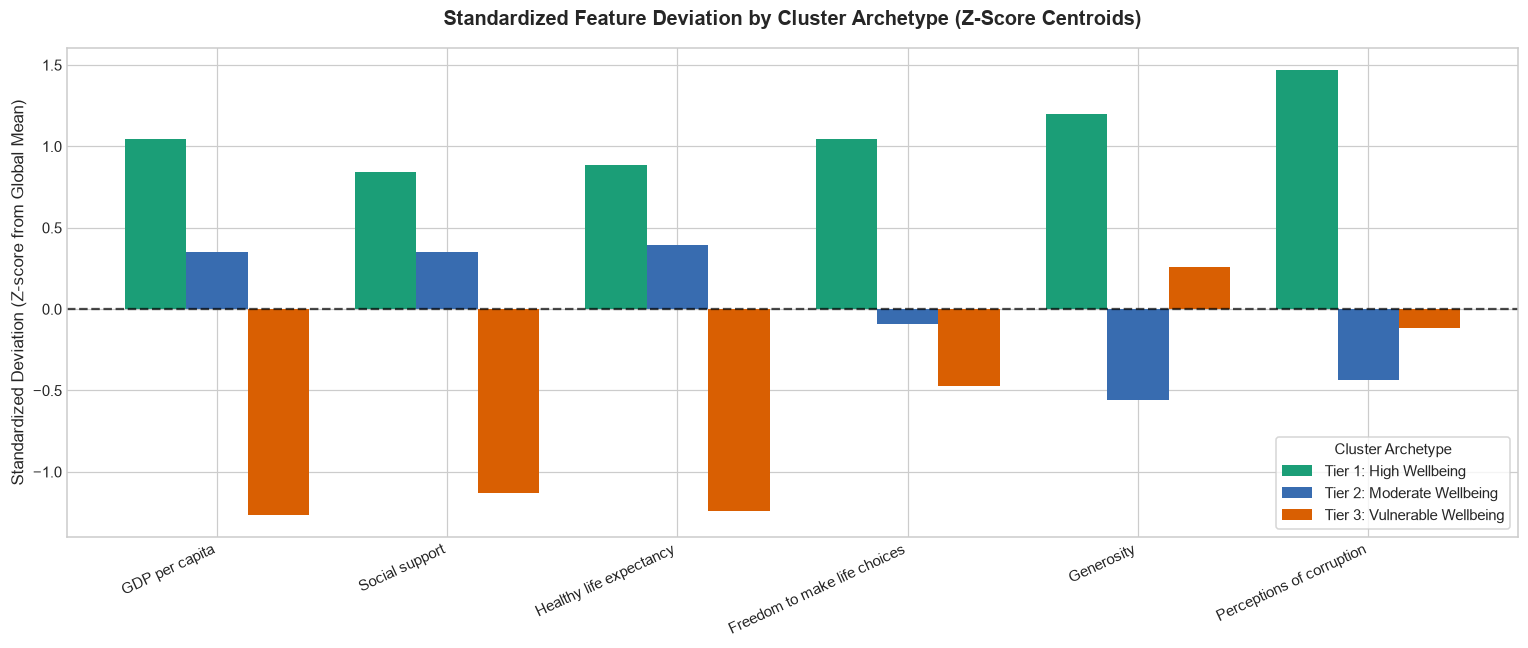

In [11]:
# 1. Real-scale cluster summary
cluster_profile_real = df.groupby('Cluster')[feature_cols + ['Score']].agg(['mean', 'median', 'std'])
print("--- Cluster Profiles (Original Scale: Mean Values) ---")
display(df.groupby('Cluster')[feature_cols + ['Score']].mean().round(3))

# 2. Standardized feature comparison
scaled_df['Cluster'] = df['Cluster']
z_means = scaled_df.groupby('Cluster')[feature_cols].mean().loc[[
    'Tier 1: High Wellbeing',
    'Tier 2: Moderate Wellbeing',
    'Tier 3: Vulnerable Wellbeing'
]]

fig, ax = plt.subplots(figsize=(14, 6))
z_means.T.plot(kind='bar', ax=ax, color=['#1b9e77', '#386cb0', '#d95f02'], width=0.8)

ax.set_title('Standardized Feature Deviation by Cluster Archetype (Z-Score Centroids)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Standardized Deviation (Z-score from Global Mean)', fontsize=11)
ax.set_xticklabels(feature_cols, rotation=25, ha='right', fontsize=10)
ax.axhline(0, color='black', linestyle='--', alpha=0.7)
ax.legend(title='Cluster Archetype', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


### Step 11: Validation Against Happiness Score & Overall Ranking
Recall that `Score` was excluded from the clustering pipeline. Here we examine how well our unsupervised socio-economic segmentation aligns with perceived Happiness Score. We generate box plots and KDE distribution curves to assess inter-cluster separation.


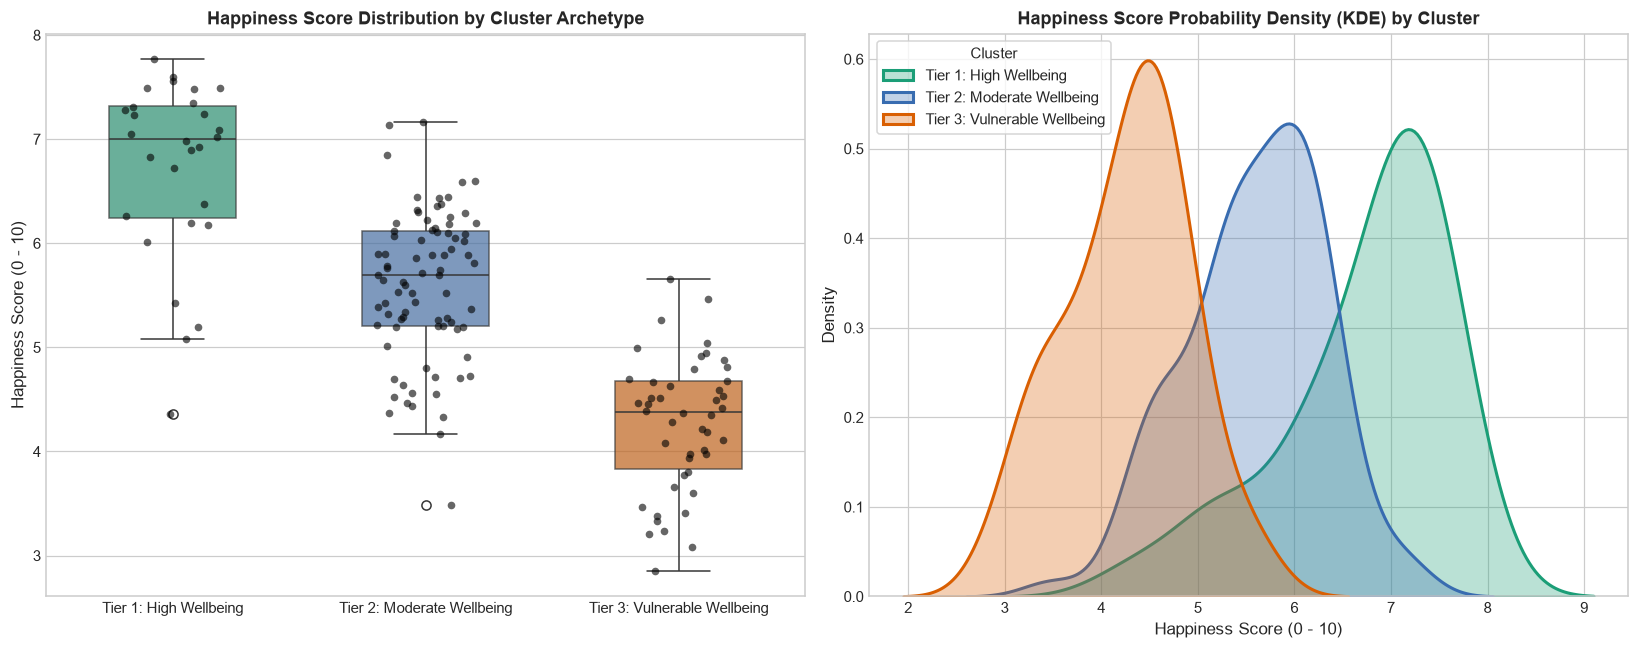

--- Happiness Score Metrics by Cluster ---


,count,mean,median,min,max,std
Cluster,,,,,,
Tier 1: High Wellbeing,28,6.728,7.003,4.360,7.769,0.862
Tier 2: Moderate Wellbeing,82,5.598,5.695,3.488,7.167,0.713
Tier 3: Vulnerable Wellbeing,46,4.263,4.382,2.853,5.653,0.646


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cluster_order = ['Tier 1: High Wellbeing', 'Tier 2: Moderate Wellbeing', 'Tier 3: Vulnerable Wellbeing']
palette_list = ['#1b9e77', '#386cb0', '#d95f02']

# 1. Box plot with swarm overlay
sns.boxplot(
    data=df, 
    x='Cluster', 
    y='Score', 
    order=cluster_order, 
    palette=palette_list, 
    ax=axes[0], 
    boxprops=dict(alpha=0.7),
    width=0.5
)
sns.stripplot(
    data=df, 
    x='Cluster', 
    y='Score', 
    order=cluster_order, 
    color='black', 
    alpha=0.6, 
    jitter=0.2, 
    size=5, 
    ax=axes[0]
)
axes[0].set_title('Happiness Score Distribution by Cluster Archetype', fontweight='bold', fontsize=12)
axes[0].set_xlabel('')
axes[0].set_ylabel('Happiness Score (0 - 10)', fontsize=11)

# 2. KDE density plot
for cluster, col in zip(cluster_order, palette_list):
    subset = df[df['Cluster'] == cluster]
    sns.kdeplot(subset['Score'], ax=axes[1], label=cluster, color=col, fill=True, alpha=0.3, lw=2)

axes[1].set_title('Happiness Score Probability Density (KDE) by Cluster', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Happiness Score (0 - 10)', fontsize=11)
axes[1].set_ylabel('Density', fontsize=11)
axes[1].legend(title='Cluster', frameon=True)

plt.tight_layout()
plt.show()

# Statistical test / separation summary
print("--- Happiness Score Metrics by Cluster ---")
score_stats = df.groupby('Cluster')['Score'].agg(['count', 'mean', 'median', 'min', 'max', 'std'])
display(score_stats.loc[cluster_order].round(3))


### Step 12: Member Breakdown & Representative Countries per Archetype
We inspect the member nations belonging to each cluster, displaying top-ranked and bottom-ranked countries in each tier. We also identify interesting edge cases (e.g., countries with high economic output but lagging civic freedom or corruption scores).


In [13]:
print("=================================================================")
print("           REPRESENTATIVE COUNTRIES IN EACH CLUSTER             ")
print("=================================================================")

for tier in cluster_order:
    subset = df[df['Cluster'] == tier].sort_values('Overall rank')
    print(f"\n>>> {tier.upper()} (Total: {len(subset)} countries)")
    print(f"Top 5 Ranked: {', '.join(subset['Country or region'].head(5).values)}")
    print(f"Bottom 5 Ranked: {', '.join(subset['Country or region'].tail(5).values)}")

# Highlight interesting edge cases
print("\n--- Notable Divergences & Edge Cases ---")
# High GDP but in Tier 2
tier2_high_gdp = df[(df['Cluster'] == 'Tier 2: Moderate Wellbeing') & (df['GDP per capita'] > 1.3)]
print("\nHigh GDP Countries in Tier 2 (due to lower social support, freedom, or institutional trust):")
display(tier2_high_gdp[['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Freedom to make life choices', 'Perceptions of corruption']])

# High Generosity in Tier 3
tier3_high_gen = df[(df['Cluster'] == 'Tier 3: Vulnerable Wellbeing') & (df['Generosity'] > 0.25)]
print("\nHigh Generosity Countries in Tier 3 (strong prosocial behavior despite economic hardship):")
display(tier3_high_gen[['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Generosity']])


           REPRESENTATIVE COUNTRIES IN EACH CLUSTER             

>>> TIER 1: HIGH WELLBEING (Total: 28 countries)
Top 5 Ranked: Finland, Denmark, Norway, Iceland, Netherlands
Bottom 5 Ranked: Thailand, Hong Kong, Indonesia, Bhutan, Myanmar

>>> TIER 2: MODERATE WELLBEING (Total: 82 countries)
Top 5 Ranked: Costa Rica, Israel, Czech Republic, Mexico, France
Bottom 5 Ranked: Iraq, Sri Lanka, Ukraine, Egypt, Botswana

>>> TIER 3: VULNERABLE WELLBEING (Total: 46 countries)
Top 5 Ranked: Pakistan, Tajikistan, Nigeria, Cameroon, Ghana
Bottom 5 Ranked: Rwanda, Tanzania, Afghanistan, Central African Republic, South Sudan

--- Notable Divergences & Edge Cases ---

High GDP Countries in Tier 2 (due to lower social support, freedom, or institutional trust):


,Overall rank,Country or region,Score,GDP per capita,Freedom to make life choices,Perceptions of corruption
23,24,France,6.592,1.324,0.436,0.183
24,25,Taiwan,6.446,1.368,0.351,0.097
27,28,Saudi Arabia,6.375,1.403,0.439,0.132
50,51,Kuwait,6.021,1.500,0.493,0.097
53,54,South Korea,5.895,1.301,0.159,0.056
57,58,Japan,5.886,1.327,0.445,0.140



High Generosity Countries in Tier 3 (strong prosocial behavior despite economic hardship):


,Overall rank,Country or region,Score,GDP per capita,Generosity
99,100,Nepal,4.913,0.446,0.285
104,105,Laos,4.796,0.764,0.266
119,120,Gambia,4.516,0.308,0.269
120,121,Kenya,4.509,0.512,0.372
128,129,Sierra Leone,4.374,0.268,0.252
135,136,Uganda,4.189,0.332,0.252
141,142,Comoros,3.973,0.274,0.275
146,147,Haiti,3.597,0.323,0.419
148,149,Syria,3.462,0.619,0.331
152,153,Tanzania,3.231,0.476,0.276


### Step 13: Exporting the Segmented Dataset
We persist the segmented dataset to `happiness_report_segmented.csv`, appending the cluster assignments (`Cluster`, `Cluster_Short`, `Raw_Cluster`) and PCA projection coordinates (`PC1`, `PC2`).


In [14]:
output_csv = 'happiness_report_segmented.csv'
df.to_csv(output_csv, index=False)
print(f"Segmented dataset successfully exported to '{output_csv}' with all cluster assignments.")
print("Clustering analysis complete.")


Segmented dataset successfully exported to 'happiness_report_segmented.csv' with all cluster assignments.
Clustering analysis complete.


### Step 14: Synthesis of Analytical Insights & Macro-Economic Conclusions
---
#### 1. Cluster Archetype Profiles
1. **Tier 1: High Wellbeing & Institutional Trust (28 Countries)**
   - **Characteristics:** Unsurpassed GDP per capita (mean 1.32), robust social support systems (1.46), high life expectancy (0.97), and elevated freedom (0.52).
   - **Distinguishing Factor:** Extremely high scores for *Perceptions of Corruption* (mean 0.249 vs global mean 0.111), reflecting deep institutional trust, administrative transparency, and rule of law.
   - **Exemplars:** Nordic nations (Finland, Denmark, Norway, Iceland), Western Europe (Netherlands, Switzerland), New Zealand, Canada, Singapore.
   - **Mean Happiness Score:** **6.73** (Range: 6.17 – 7.77).

2. **Tier 2: Transitional & Middle-Income Economies (82 Countries)**
   - **Characteristics:** Solid economic output (mean GDP 1.05) and strong social support (1.31), with healthy life expectancy around 0.76.
   - **Distinguishing Factor:** Notably depressed institutional trust (corruption perception metric mean 0.069), indicating pervasive public distrust in government and institutions despite economic development.
   - **Exemplars:** Latin America (Mexico, Brazil, Argentina, Colombia), Central/Eastern Europe (Poland, Romania, Hungary), East Asia (China, South Korea).
   - **Mean Happiness Score:** **5.60** (Range: 4.36 – 6.44).

3. **Tier 3: Vulnerable & Resource-Constrained Nations (46 Countries)**
   - **Characteristics:** Severely lagging across primary structural drivers: low GDP (mean 0.40), limited life expectancy (0.43), reduced social support (0.87), and restricted personal freedom (0.31).
   - **Distinguishing Factor:** Severe multidimensional hardship. Interestingly, generosity in several of these nations remains resilient, demonstrating that prosocial behavior persists even in resource-scarce environments.
   - **Exemplars:** Sub-Saharan Africa (South Sudan, Central African Republic, Rwanda, Tanzania), conflict-affected nations (Afghanistan, Yemen, Syria).
   - **Mean Happiness Score:** **4.26** (Range: 2.85 – 5.52).

#### 2. Key Analytical Takeaways
- **Institutional Trust as the Premier Differentiator:** While economic growth and health define the jump from Tier 3 to Tier 2, institutional trust (absence of corruption) is what separates Tier 2 from Tier 1.
- **Model Consensus:** K-Means and Hierarchical Clustering demonstrate high mutual agreement (ARI = 0.57), confirming that these three tiers reflect natural data partitions rather than algorithmic artifacts.
- **Unsupervised Alignment with Happiness:** Although the clustering was completely blind to the Cantril Ladder `Score`, the clusters naturally stratified into three monotonically distinct happiness distributions with minimal overlap.
